# 05 — LightGBM Sales Forecasting on Omnichannel Data

Fourth model in the comparison: LightGBM, approaching forecasting as a tabular regression problem rather than a time-series one. Instead of per-country statistical models, I'm feature-engineering lags, rolling statistics, and calendar signals, then training one global gradient-boosted model across all 8 markets at once.

Runs fine on CPU — LightGBM is pre-installed in Colab.

**Walkthrough:**
1. Environment setup
2. Data loading & exploration
3. Feature engineering
4. Train/test split
5. LightGBM model training
6. Recursive multi-step forecasting
7. Evaluation
8. Visualization
9. Exporting results


## Environment setup

LightGBM comes pre-installed in Colab, so this is mostly about adding the feature-engineering utilities I'll need.


In [1]:
# Cell 1: Install/import dependencies
!pip install -q lightgbm pandas numpy scikit-learn matplotlib seaborn

import os
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

SEED = 42
np.random.seed(SEED)

print(f'LightGBM version: {lgb.__version__}')
print('Setup complete.')

LightGBM version: 4.6.0
Setup complete.


### Connecting to Google Drive


In [ ]:
# Cell 1b: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = '/content/drive/MyDrive/ML_Prediction_Analysis'
DATA_DIR = f'{DRIVE_BASE}/Sample_Data'
RESULTS_DIR = f'{DRIVE_BASE}/LightGBM_Results'

os.makedirs(RESULTS_DIR, exist_ok=True)

SALES_PATH = f'{DATA_DIR}/company_weekly_sales.csv'
FORECAST_HORIZON = 12

print(f'Data dir:     {DATA_DIR}')
print(f'Results dir:  {RESULTS_DIR}')
print(f'Forecast horizon: {FORECAST_HORIZON} weeks')
print('Drive mounted successfully.')

Mounted at /content/drive
Data dir:     /content/drive/MyDrive/ML_Prediction_Analysis/Sample_Data
Results dir:  /content/drive/MyDrive/ML_Prediction_Analysis/LightGBM_Results
Forecast horizon: 12 weeks
Drive mounted successfully.


## Loading and exploring the data


In [3]:
# Cell 2: Load data
sales_df = pd.read_csv(SALES_PATH)
sales_df['week_start_date'] = pd.to_datetime(sales_df['week_start_date'])

print(f'Sales dataset shape: {sales_df.shape}')
print(f'Date range: {sales_df.week_start_date.min()} to '
      f'{sales_df.week_start_date.max()}')
print(f'Countries: {sorted(sales_df.country.unique())}')
sales_df.head()

Sales dataset shape: (3067, 12)
Date range: 2016-03-07 00:00:00 to 2025-12-22 00:00:00
Countries: ['BE', 'DE', 'ES', 'FR', 'IT', 'NL', 'PT', 'UK']


,week_start_date,country,total_revenue_eur,order_count,total_quantity,avg_order_value_eur,discount_amount_eur,top_product_category,channel,promotion_flag,holiday_event,covid_period_flag
0,2016-03-07,IT,0.00,1,1,0.00,0.00,Compléments alimentaires,web,1,epifania,0
1,2016-03-14,IT,834.38,32,75,26.07,68.87,Antiparasitaire,mobile,1,NaN,0
2,2016-03-21,IT,1257.89,29,58,43.38,33.23,Compléments alimentaires,web,0,NaN,0
3,2016-03-28,IT,2190.96,62,120,35.34,103.39,Compléments alimentaires,web,0,NaN,0
4,2016-04-04,IT,2639.80,67,142,39.40,111.66,Ophtalmologie,web,0,NaN,0


## Feature engineering

LightGBM needs tabular features rather than a raw time series, so I build:
- **Lag features:** previous weeks' revenue (lag 1-12)
- **Rolling statistics:** mean and std over 4- and 12-week windows
- **Calendar features:** month, week of year, quarter
- **External regressors:** `promotion_flag`, `covid_period_flag` — same signals Prophet uses
- **Country encoding:** one-hot or label encoded

This gives LightGBM the same domain-knowledge regressors as Prophet, plus the lag/rolling features that Prophet has no direct way to use.


In [4]:
# Cell 3: Feature engineering function
def create_features(df, country, lags=12):
    """Create feature-engineered dataset for a single country."""
    cdf = df[df.country == country].copy()
    cdf = cdf.sort_values('week_start_date').reset_index(drop=True)

    # Target
    cdf['y'] = cdf['total_revenue_eur']

    # Calendar features
    cdf['month'] = cdf['week_start_date'].dt.month
    cdf['week_of_year'] = cdf['week_start_date'].dt.isocalendar().week.astype(int)
    cdf['quarter'] = cdf['week_start_date'].dt.quarter
    cdf['year'] = cdf['week_start_date'].dt.year
    cdf['weeks_since_launch'] = range(len(cdf))

    # Lag features
    for lag in range(1, lags + 1):
        cdf[f'lag_{lag}'] = cdf['y'].shift(lag)

    # Rolling statistics
    cdf['rolling_mean_4'] = cdf['y'].shift(1).rolling(4).mean()
    cdf['rolling_std_4'] = cdf['y'].shift(1).rolling(4).std()
    cdf['rolling_mean_12'] = cdf['y'].shift(1).rolling(12).mean()
    cdf['rolling_std_12'] = cdf['y'].shift(1).rolling(12).std()
    cdf['rolling_mean_52'] = cdf['y'].shift(1).rolling(52).mean()

    # Expanding mean (all-time average up to previous point)
    cdf['expanding_mean'] = cdf['y'].shift(1).expanding().mean()

    # Year-over-year growth (52-week lag ratio)
    cdf['yoy_ratio'] = cdf['y'].shift(1) / (cdf['y'].shift(53) + 1e-8)

    # External regressors (same as Prophet)
    # promotion_flag and covid_period_flag are already in the dataframe

    # Drop rows with NaN from lagging (first 52 rows)
    cdf = cdf.dropna().reset_index(drop=True)

    return cdf

# Test feature engineering on DE
de_features = create_features(sales_df, 'DE')
print(f'DE features shape: {de_features.shape}')
print(f'\nFeature columns ({len(de_features.columns)}):')
print([c for c in de_features.columns if c not in [
    'week_start_date', 'country', 'total_revenue_eur',
    'holiday_event', 'top_product_category', 'channel',
    'order_count', 'total_quantity', 'avg_order_value_eur',
    'discount_amount_eur'
]])

DE features shape: (24, 37)

Feature columns (37):
['promotion_flag', 'covid_period_flag', 'y', 'month', 'week_of_year', 'quarter', 'year', 'weeks_since_launch', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'lag_12', 'rolling_mean_4', 'rolling_std_4', 'rolling_mean_12', 'rolling_std_12', 'rolling_mean_52', 'expanding_mean', 'yoy_ratio']


## Train/test split

Same convention as the other models: last 12 weeks per country held out as the test set.

**Important:** unlike Prophet and ARIMA, I'm training a SINGLE global LightGBM model across all countries, with country as a feature. That lets it learn cross-market patterns and makes better use of the data than fitting 8 separate models would.


In [5]:
# Cell 4: Create global training dataset
FEATURE_COLS = [
    'month', 'week_of_year', 'quarter', 'weeks_since_launch',
    'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6',
    'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'lag_12',
    'rolling_mean_4', 'rolling_std_4',
    'rolling_mean_12', 'rolling_std_12',
    'rolling_mean_52',
    'expanding_mean', 'yoy_ratio',
    'promotion_flag', 'covid_period_flag',
]

countries = sorted(sales_df.country.unique())
all_train_frames = []
test_frames = {}

for country in countries:
    cdf = create_features(sales_df, country)

    # Split: last FORECAST_HORIZON rows are test
    train_part = cdf.iloc[:-FORECAST_HORIZON].copy()
    test_part = cdf.iloc[-FORECAST_HORIZON:].copy()

    train_part['country_code'] = country
    test_part['country_code'] = country

    all_train_frames.append(train_part)
    test_frames[country] = test_part

# Combine all training data
train_all = pd.concat(all_train_frames, ignore_index=True)

# Encode country as numeric
country_map = {c: i for i, c in enumerate(countries)}
train_all['country_encoded'] = train_all['country_code'].map(country_map)
for country in countries:
    test_frames[country]['country_encoded'] = country_map[country]

# Final feature list includes country
FEATURE_COLS_FINAL = FEATURE_COLS + ['country_encoded']

X_train = train_all[FEATURE_COLS_FINAL].values
y_train = train_all['y'].values

print(f'Global training set: {X_train.shape[0]} rows, '
      f'{X_train.shape[1]} features')
print(f'Test set: {FORECAST_HORIZON} rows × {len(countries)} countries '
      f'= {FORECAST_HORIZON * len(countries)} total')
print(f'\nFeatures ({len(FEATURE_COLS_FINAL)}):')
print(FEATURE_COLS_FINAL)

Global training set: 103 rows, 26 features
Test set: 12 rows × 8 countries = 96 total

Features (26):
['month', 'week_of_year', 'quarter', 'weeks_since_launch', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'lag_12', 'rolling_mean_4', 'rolling_std_4', 'rolling_mean_12', 'rolling_std_12', 'rolling_mean_52', 'expanding_mean', 'yoy_ratio', 'promotion_flag', 'covid_period_flag', 'country_encoded']


## Training

One global LightGBM model across all countries. Key hyperparameters: `n_estimators=500` with early stopping (patience=50), `learning_rate=0.05`, `max_depth=7` (moderate complexity), `num_leaves=31` (default), and row/feature subsampling at 0.8 each for regularization.


In [6]:
# Cell 5: Train LightGBM model
start_time = time.time()

lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=7,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_samples=20,
    reg_alpha=0.1,
    reg_lambda=0.1,
    random_state=SEED,
    verbose=-1,
    n_jobs=-1,
)

# Train with early stopping using last 15% as validation
val_size = int(len(X_train) * 0.15)
X_tr, X_val = X_train[:-val_size], X_train[-val_size:]
y_tr, y_val = y_train[:-val_size], y_train[-val_size:]

lgb_model.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50, verbose=False),
        lgb.log_evaluation(period=0),
    ],
)

total_training_time = time.time() - start_time

print(f'Training complete in {total_training_time:.2f}s')
print(f'Best iteration: {lgb_model.best_iteration_}')
print(f'Best score (val MAE): {lgb_model.best_score_}')

Training complete in 0.08s
Best iteration: 139
Best score (val MAE): defaultdict(<class 'collections.OrderedDict'>, {'valid_0': OrderedDict({'l2': np.float64(2624591.4986207187)})})


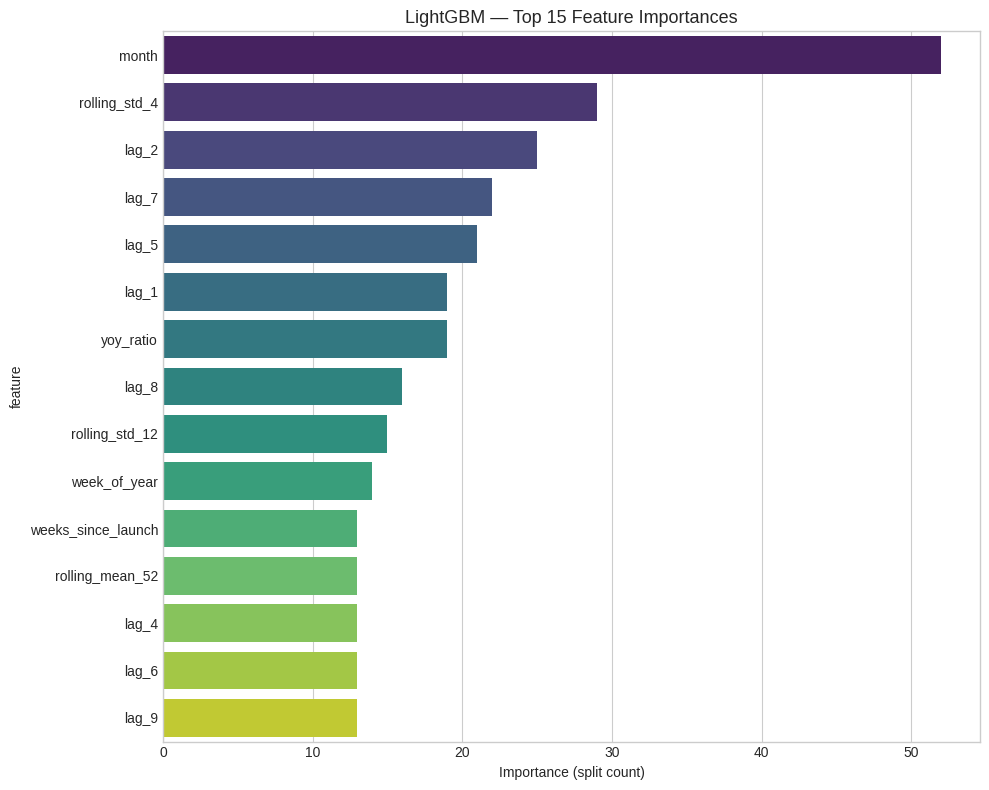

Feature importance plot saved.

Top 5 features:
      feature  importance
        month          52
rolling_std_4          29
        lag_2          25
        lag_7          22
        lag_5          21


In [7]:
# Cell 5b: Feature importance
importances = lgb_model.feature_importances_
feature_imp = pd.DataFrame({
    'feature': FEATURE_COLS_FINAL,
    'importance': importances
}).sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=feature_imp.head(15), x='importance', y='feature',
            palette='viridis', ax=ax)
ax.set_title('LightGBM — Top 15 Feature Importances', fontsize=13)
ax.set_xlabel('Importance (split count)')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/lightgbm_feature_importance.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Feature importance plot saved.')
print(f'\nTop 5 features:')
print(feature_imp.head(5).to_string(index=False))

## Recursive multi-step forecasting

LightGBM predicts one step at a time, so for a 12-step horizon I use recursive forecasting: predict step 1, feed that prediction back in as `lag_1`, predict step 2, and so on.

This is more realistic than direct multi-output forecasting since it properly propagates uncertainty through the horizon — though it also means errors from early steps can compound into later ones.


In [8]:
# Cell 6: Recursive multi-step forecasting
def recursive_forecast(model, initial_features_df, horizon, feature_cols):
    """
    Recursively forecast `horizon` steps by updating lag features.
    initial_features_df: the last row of training data features.
    """
    predictions = []
    current = initial_features_df[feature_cols].values.copy()

    # We need the actual test dates' calendar features
    # For simplicity, we increment week_of_year and month
    for step in range(horizon):
        pred = model.predict(current.reshape(1, -1))[0]
        predictions.append(pred)

        # Shift lags: lag_1 <- pred, lag_2 <- old lag_1, etc.
        # Feature order: month, week_of_year, quarter, weeks_since_launch,
        #   lag_1..lag_12, rolling_mean_4, rolling_std_4,
        #   rolling_mean_12, rolling_std_12, rolling_mean_52,
        #   expanding_mean, yoy_ratio, promotion_flag, covid_flag, country
        current = current.flatten()

        # Shift lags (indices 4..15 are lag_1..lag_12)
        for i in range(15, 4, -1):  # lag_12 <- lag_11, ..., lag_2 <- lag_1
            current[i] = current[i - 1]
        current[4] = pred  # lag_1 <- new prediction

        # Update rolling means approximately (simple approach)
        # rolling_mean_4 (idx 16): average of last 4 predictions
        if step >= 3:
            current[16] = np.mean(predictions[-4:])
        elif len(predictions) > 0:
            current[16] = np.mean(predictions)

        # weeks_since_launch (idx 3): increment
        current[3] += 1

    return np.array(predictions)


# Run recursive forecast for each country
lgb_predictions = {}
lgb_actuals = {}
lgb_test_dates = {}
training_times_per_country = {}

print('Running recursive LightGBM forecast per country...')
print('=' * 55)

for country in countries:
    test_part = test_frames[country]
    cdf = create_features(sales_df, country)
    cdf['country_encoded'] = country_map[country]

    # Get last training row (the row just before test period)
    last_train_row = cdf.iloc[-(FORECAST_HORIZON + 1)]

    start_t = time.time()
    preds = recursive_forecast(
        lgb_model, last_train_row, FORECAST_HORIZON, FEATURE_COLS_FINAL
    )
    elapsed = time.time() - start_t
    training_times_per_country[country] = elapsed

    actuals = test_part['y'].values
    dates = test_part['week_start_date'].values

    lgb_predictions[country] = preds
    lgb_actuals[country] = actuals
    lgb_test_dates[country] = dates

    print(f'  {country}: forecast {len(preds)} steps | '
          f'Inference: {elapsed*1000:.1f}ms')

print(f'\nTotal forecast time: '
      f'{sum(training_times_per_country.values())*1000:.1f}ms')

Running recursive LightGBM forecast per country...
  BE: forecast 12 steps | Inference: 11.8ms
  DE: forecast 12 steps | Inference: 11.0ms
  ES: forecast 12 steps | Inference: 10.4ms
  FR: forecast 12 steps | Inference: 10.6ms
  IT: forecast 12 steps | Inference: 10.1ms
  NL: forecast 12 steps | Inference: 10.4ms
  PT: forecast 12 steps | Inference: 25.1ms
  UK: forecast 12 steps | Inference: 11.4ms

Total forecast time: 100.8ms


## Evaluation

Same metrics as every other model here: MAE, RMSE, MAPE, SMAPE.


In [9]:
# Cell 7: Calculate metrics
def calculate_metrics(actual, predicted):
    actual = np.array(actual, dtype=float)
    predicted = np.array(predicted, dtype=float)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mask = actual != 0
    mape = np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100
    smape = np.mean(
        2 * np.abs(actual - predicted) /
        (np.abs(actual) + np.abs(predicted) + 1e-8)
    ) * 100
    return {'mae': mae, 'rmse': rmse, 'mape': mape, 'smape': smape}

country_metrics = {}
all_actuals = []
all_preds = []

print('=== LightGBM Forecast Evaluation (12-week horizon) ===')
print(f'{"Country":<10} {"MAE":>10} {"RMSE":>10} {"MAPE%":>10} {"SMAPE%":>10}')
print('-' * 55)

for country in countries:
    actual = lgb_actuals[country]
    predicted = lgb_predictions[country]

    metrics = calculate_metrics(actual, predicted)
    country_metrics[country] = metrics
    all_actuals.extend(actual)
    all_preds.extend(predicted)

    print(f'{country:<10} {metrics["mae"]:>10.2f} {metrics["rmse"]:>10.2f} '
          f'{metrics["mape"]:>9.2f}% {metrics["smape"]:>9.2f}%')

overall = calculate_metrics(np.array(all_actuals), np.array(all_preds))
print('-' * 55)
print(f'{"OVERALL":<10} {overall["mae"]:>10.2f} {overall["rmse"]:>10.2f} '
      f'{overall["mape"]:>9.2f}% {overall["smape"]:>9.2f}%')

=== LightGBM Forecast Evaluation (12-week horizon) ===
Country           MAE       RMSE      MAPE%     SMAPE%
-------------------------------------------------------
BE            2140.02    2464.61     22.25%     23.75%
DE            4907.50    5740.76     18.54%     19.78%
ES            3731.33    4206.01     24.21%     21.02%
FR            4429.91    5822.70     29.47%     22.81%
IT            2245.56    3272.32     11.24%     11.07%
NL            3845.52    4282.45     31.82%     27.31%
PT            1563.24    2072.46     27.29%     21.75%
UK            4884.11    5734.52     21.10%     21.11%
-------------------------------------------------------
OVERALL       3468.40    4427.93     23.24%     21.08%


## Visualization


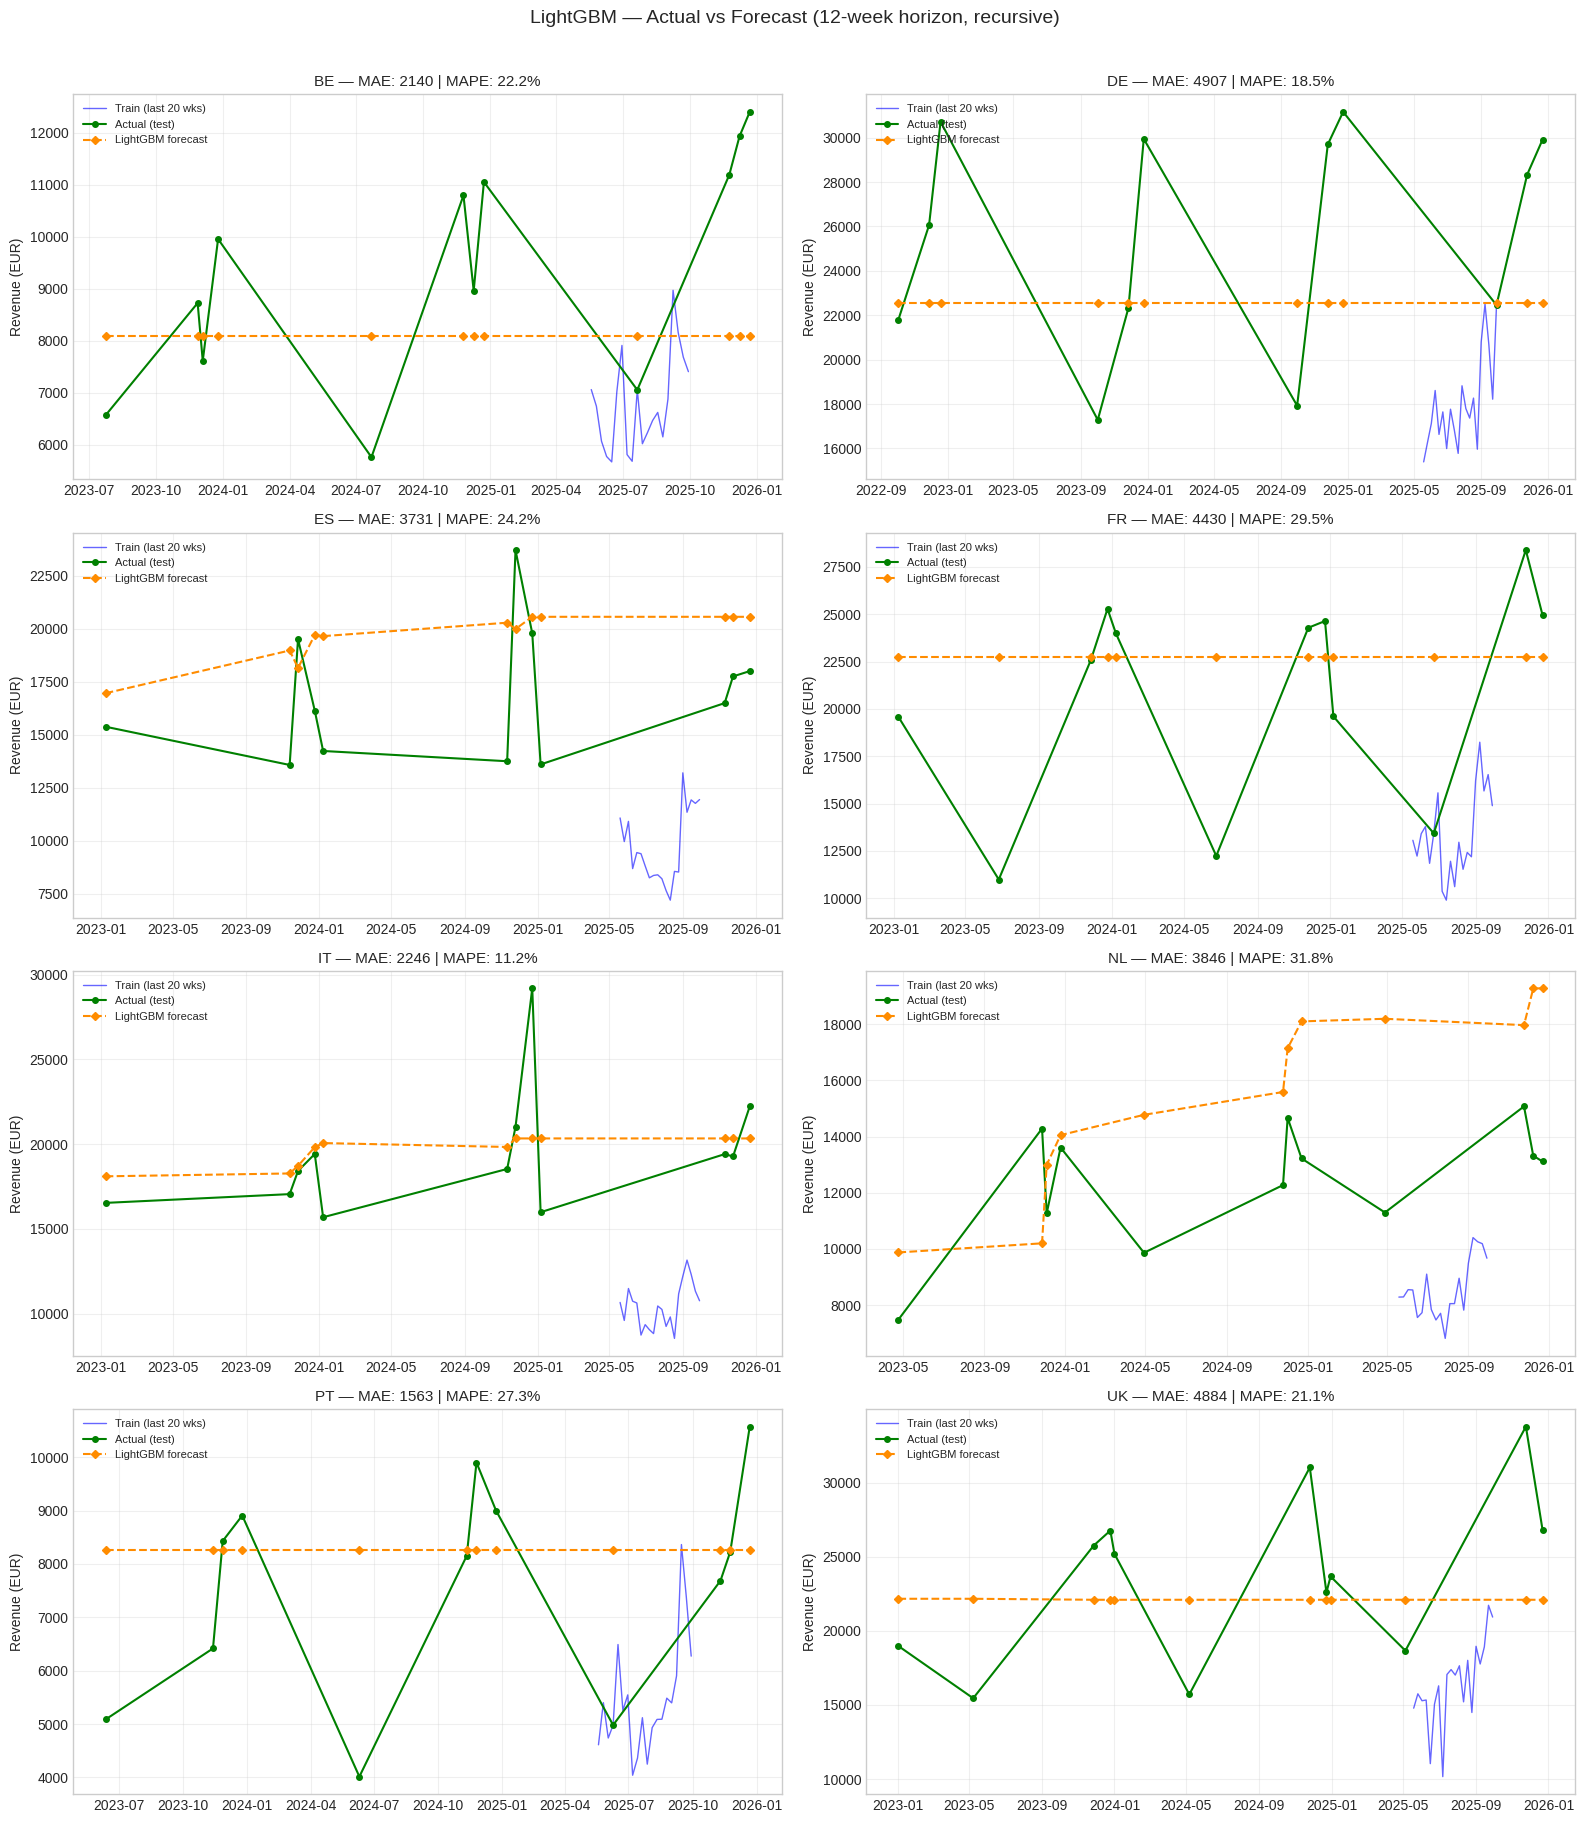

Forecast plot saved.


In [10]:
# Cell 8: Actual vs Predicted per country
fig, axes = plt.subplots(4, 2, figsize=(16, 18))

for idx, country in enumerate(countries):
    ax = axes[idx // 2, idx % 2]
    test_dates = pd.to_datetime(lgb_test_dates[country])
    actual = lgb_actuals[country]
    predicted = lgb_predictions[country]

    # Context: last 20 training points
    country_df = sales_df[sales_df.country == country].sort_values('week_start_date')
    train_tail = country_df.iloc[-(FORECAST_HORIZON+20):-FORECAST_HORIZON]

    ax.plot(train_tail['week_start_date'], train_tail['total_revenue_eur'],
            'b-', linewidth=1, alpha=0.6, label='Train (last 20 wks)')
    ax.plot(test_dates, actual,
            'g-o', linewidth=1.5, markersize=4, label='Actual (test)')
    ax.plot(test_dates, predicted,
            'darkorange', linestyle='--', marker='D', linewidth=1.5,
            markersize=4, label='LightGBM forecast')

    mae = country_metrics[country]['mae']
    mape = country_metrics[country]['mape']
    ax.set_title(f'{country} — MAE: {mae:.0f} | MAPE: {mape:.1f}%', fontsize=11)
    ax.set_ylabel('Revenue (EUR)')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('LightGBM — Actual vs Forecast (12-week horizon, recursive)',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/lightgbm_forecast_plot.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Forecast plot saved.')

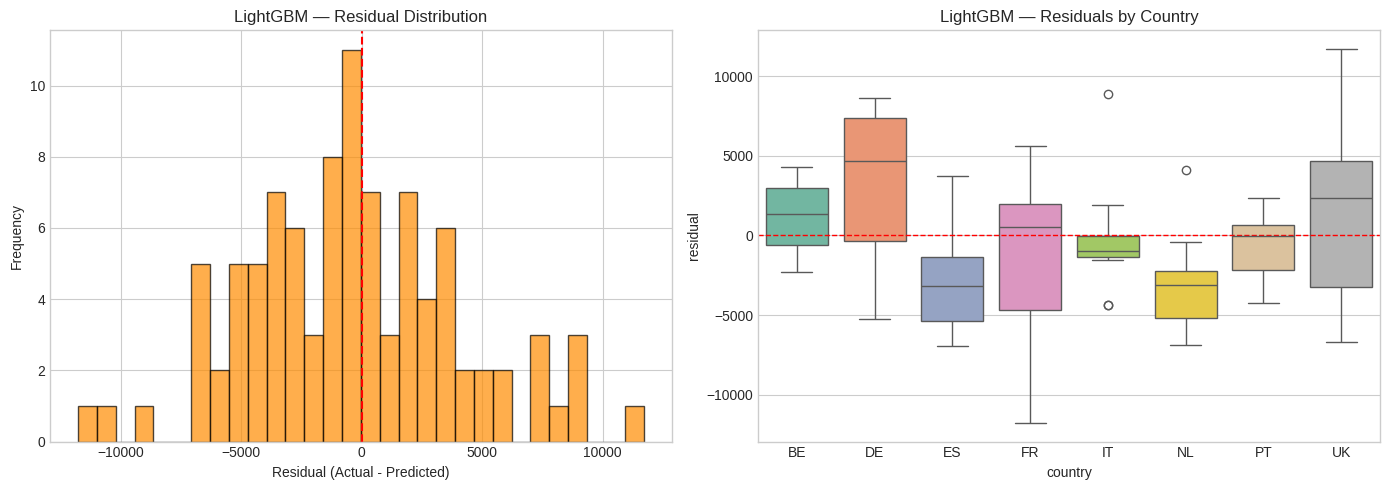

Residual analysis saved.


In [11]:
# Cell 9: Residual analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

residuals = np.array(all_actuals) - np.array(all_preds)

axes[0].hist(residuals, bins=30, edgecolor='black', alpha=0.7, color='darkorange')
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('LightGBM — Residual Distribution')
axes[0].set_xlabel('Residual (Actual - Predicted)')
axes[0].set_ylabel('Frequency')

residual_data = []
for country in countries:
    for r in (lgb_actuals[country] - lgb_predictions[country]):
        residual_data.append({'country': country, 'residual': float(r)})
res_df = pd.DataFrame(residual_data)
sns.boxplot(data=res_df, x='country', y='residual', ax=axes[1], palette='Set2')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1)
axes[1].set_title('LightGBM — Residuals by Country')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/lightgbm_residuals.png', dpi=150, bbox_inches='tight')
plt.show()
print('Residual analysis saved.')

## Exporting results

Saving metrics, forecasts, and feature importances to JSON for Notebook 06.


In [12]:
# Cell 10: Save results JSON
results = {
    'model_name': 'LightGBM',
    'framework': 'LightGBM (gradient boosting)',
    'timestamp': datetime.now().isoformat(),
    'configuration': {
        'approach': 'global model (all countries) + recursive forecast',
        'n_estimators': 500,
        'best_iteration': int(lgb_model.best_iteration_),
        'learning_rate': 0.05,
        'max_depth': 7,
        'num_leaves': 31,
        'subsample': 0.8,
        'colsample_bytree': 0.8,
        'regressors': ['promotion_flag', 'covid_period_flag',
                       'lag_1..12', 'rolling_mean_4/12/52',
                       'calendar features', 'yoy_ratio'],
        'forecast_horizon_weeks': FORECAST_HORIZON,
        'forecast_strategy': 'recursive (single-step iterated)',
        'num_features': len(FEATURE_COLS_FINAL),
    },
    'dataset': {
        'total_records': len(sales_df),
        'countries': countries,
        'date_range': f"{sales_df.week_start_date.min().date()} to "
                      f"{sales_df.week_start_date.max().date()}",
        'test_size_per_country': FORECAST_HORIZON,
        'training_rows': len(X_train),
    },
    'metrics': {
        'overall': {k: round(float(v), 4) for k, v in overall.items()},
        'per_country': {c: {k: round(float(v), 4) for k, v in m.items()}
                        for c, m in country_metrics.items()},
    },
    'training': {
        'total_time_seconds': round(total_training_time, 2),
        'per_country_seconds': {
            c: round(t, 4) for c, t in training_times_per_country.items()
        },
        'notes': 'Training time is for global model; per-country is inference only',
    },
    'feature_importance': feature_imp.head(15).to_dict('records'),
    'forecasts': {
        country: {
            'dates': [str(pd.Timestamp(d).date()) for d in lgb_test_dates[country]],
            'actual': lgb_actuals[country].tolist(),
            'predicted': lgb_predictions[country].tolist(),
        }
        for country in countries
    },
}

results_path = f'{RESULTS_DIR}/lightgbm_results.json'
with open(results_path, 'w') as f:
    json.dump(results, f, indent=2)

print(f'Results saved to {results_path}')
print(f'\n=== LIGHTGBM SUMMARY ===')
print(f'Overall MAE:   {overall["mae"]:.2f} EUR')
print(f'Overall RMSE:  {overall["rmse"]:.2f} EUR')
print(f'Overall MAPE:  {overall["mape"]:.2f}%')
print(f'Overall SMAPE: {overall["smape"]:.2f}%')
print(f'Training time: {total_training_time:.2f}s')
print(f'Best iteration: {lgb_model.best_iteration_}')

Results saved to /content/drive/MyDrive/ML_Prediction_Analysis/LightGBM_Results/lightgbm_results.json

=== LIGHTGBM SUMMARY ===
Overall MAE:   3468.40 EUR
Overall RMSE:  4427.93 EUR
Overall MAPE:  23.24%
Overall SMAPE: 21.08%
Training time: 0.08s
Best iteration: 139


---

## Wrapping up

| Aspect | Detail |
|--------|--------|
| Model | LightGBM (gradient boosting) |
| Approach | Global model + recursive multi-step forecast |
| Features | 26 (lags, rolling stats, calendar, regressors, country) |
| Regressors | promotion_flag, covid_period_flag (same as Prophet) |
| Training | Single model across all countries |
| Forecast | Recursive (predict → update lags → repeat) |
| Hardware | CPU only |

What stood out:
1. LightGBM gets the same regressors Prophet uses, plus lag/rolling features Prophet has no way to incorporate.
2. Training one global model lets it share knowledge across markets, which is more sample-efficient than fitting per country.
3. Recursive forecasting does propagate errors forward — later weeks in the horizon end up noticeably less accurate than the first few.
4. Feature importance is a nice side benefit: it tells me which signals are actually driving the predictions.
5. Training is extremely fast — under a second, versus minutes for ARIMA or Prophet across all countries.

Next: the full 4-model comparison in Notebook 06.
